In [4]:
import pandas as pd 
import os
import numpy as np 
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [5]:
raw_df = pd.read_csv('C:/LEARNED/epics-carbon-platform/data/raw/updated_crop_recommendation.csv')
raw_df.head(5)

,N,P,K,temperature,humidity,ph,rainfall,label
0,90.0,42.0,43.0,20.879744,82.002744,6.502985,202.935536,rice
1,85.0,58.0,41.0,21.770462,80.319644,7.038096,226.655537,rice
2,60.0,55.0,44.0,23.004459,82.320763,7.840207,263.964248,rice
3,74.0,35.0,40.0,26.491096,80.158363,6.980401,242.864034,rice
4,78.0,42.0,42.0,20.130175,81.604873,7.628473,262.717340,rice


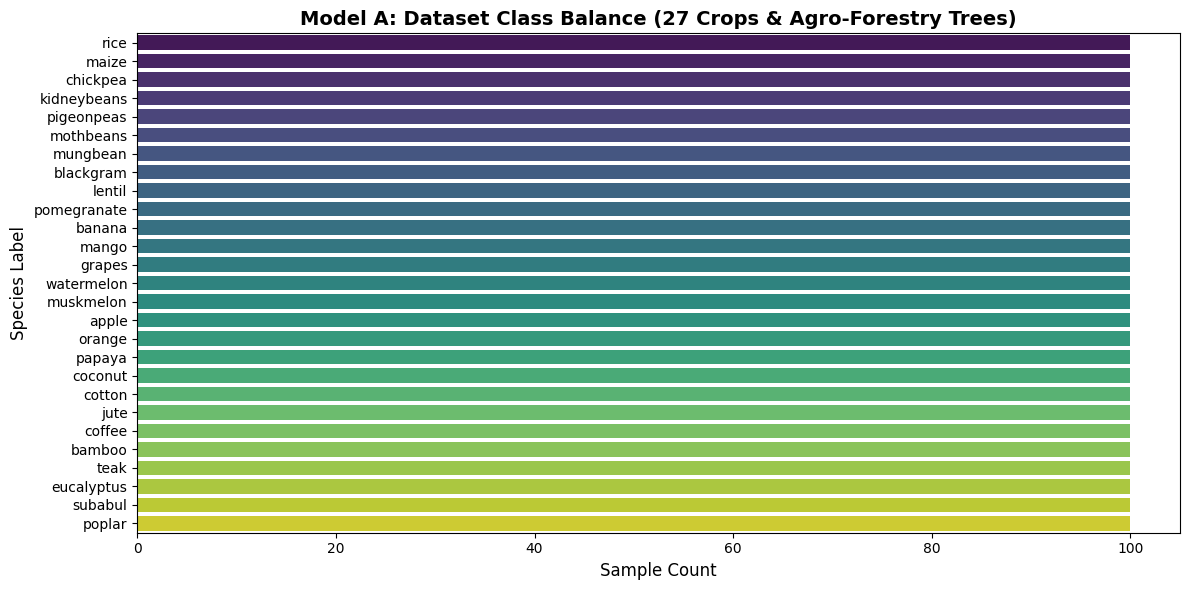

In [7]:
plt.figure(figsize=(12, 6))
species_counts = raw_df['label'].value_counts()

sns.barplot(
    x=species_counts.values, 
    y=species_counts.index, 
    hue=species_counts.index,
    palette="viridis"
)

plt.title("Model A: Dataset Class Balance (27 Crops & Agro-Forestry Trees)", fontsize=14, fontweight='bold')
plt.xlabel("Sample Count", fontsize=12)
plt.ylabel("Species Label", fontsize=12)
plt.tight_layout()
plt.show()

In [10]:
X=raw_df.iloc[:,:7]
X.head(5)

,N,P,K,temperature,humidity,ph,rainfall
0,90.0,42.0,43.0,20.879744,82.002744,6.502985,202.935536
1,85.0,58.0,41.0,21.770462,80.319644,7.038096,226.655537
2,60.0,55.0,44.0,23.004459,82.320763,7.840207,263.964248
3,74.0,35.0,40.0,26.491096,80.158363,6.980401,242.864034
4,78.0,42.0,42.0,20.130175,81.604873,7.628473,262.717340


In [11]:
y=raw_df['label']
y.head(5)

0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: object

In [12]:
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

In [13]:
rf=RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [14]:
ypred=rf.predict(X_test)

In [15]:
accuracy_val=accuracy_score(y_test,ypred)
accuracy_val

0.987037037037037

In [16]:
class_report=classification_report(y_test, ypred)
print(class_report)

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      bamboo       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
  eucalyptus       0.94      0.85      0.89        20
      grapes       1.00      1.00      1.00        20
        jute       0.87      1.00      0.93        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00    

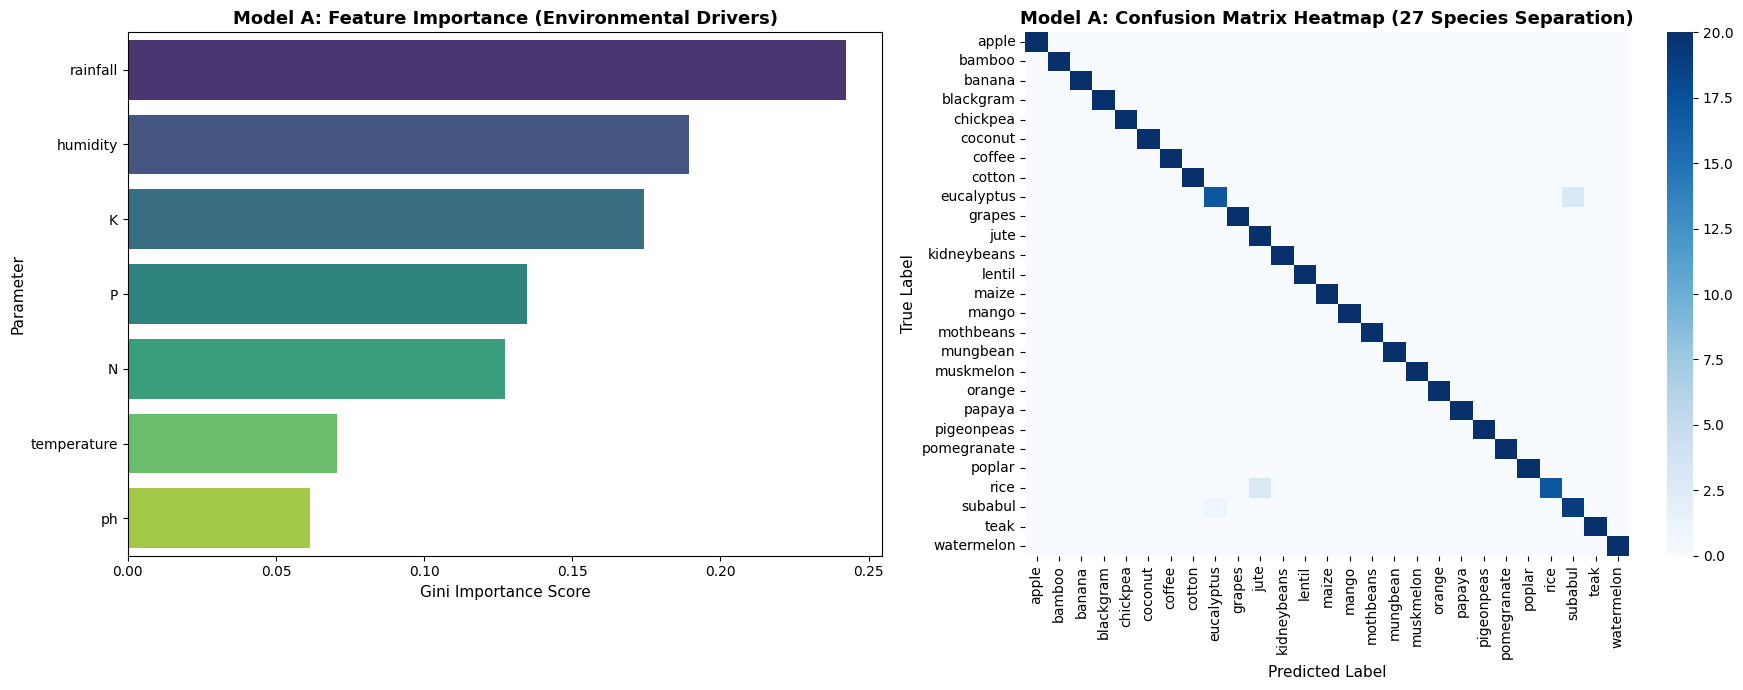

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot A: Feature Importance (Gini Score)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

sns.barplot(
    x=importances.values, 
    y=importances.index, 
    hue=importances.index,
    legend=False,
    palette="viridis",
    ax=axes[0]
)
axes[0].set_title("Model A: Feature Importance (Environmental Drivers)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Gini Importance Score", fontsize=11)
axes[0].set_ylabel("Parameter", fontsize=11)

# Plot B: Multi-Class Confusion Matrix (27 Species)
cm = confusion_matrix(y_test, ypred)

sns.heatmap(
    cm, 
    annot=False, 
    cmap="Blues", 
    xticklabels=rf.classes_, 
    yticklabels=rf.classes_,
    ax=axes[1],
    cbar=True
)
axes[1].set_title("Model A: Confusion Matrix Heatmap (27 Species Separation)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].set_ylabel("True Label", fontsize=11)
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

In [39]:
import joblib

# Set the export directory path
export_dir = '../exported_models'
os.makedirs(export_dir, exist_ok=True)

#  full output file path
model_output_path = os.path.join(export_dir, 'survival_model.pkl')

# To save the trained model artifact to disk
joblib.dump(rf, model_output_path)
print(f"Model saved successfully to: {model_output_path}")

Model saved successfully to: ../exported_models\survival_model.pkl


**Inference Test Code**

In [54]:
model = joblib.load('../exported_models/survival_model.pkl')

# 1. Simulate single farmer soil & weather input
sample_farmer_input=pd.DataFrame([{
    'N': 35, 'P': 25, 'K': 30,
    'temperature': 25.0, 'humidity': 55.0,
    'ph': 7.0, 'rainfall': 800.0
}])


# 2. Extract species names and generate survival probabilities
species_list = model.classes_
raw_probabilities = model.predict_proba(sample_farmer_input)[0]

# 3. Pair species with their probability scores
survival_scores = dict(zip(species_list, raw_probabilities))

# Display top surviving species
sorted_scores = dict(sorted(survival_scores.items(), key=lambda item: item[1], reverse=True))
print(sorted_scores)

{'subabul': np.float64(0.52), 'eucalyptus': np.float64(0.47), 'mango': np.float64(0.01), 'apple': np.float64(0.0), 'bamboo': np.float64(0.0), 'banana': np.float64(0.0), 'blackgram': np.float64(0.0), 'chickpea': np.float64(0.0), 'coconut': np.float64(0.0), 'coffee': np.float64(0.0), 'cotton': np.float64(0.0), 'grapes': np.float64(0.0), 'jute': np.float64(0.0), 'kidneybeans': np.float64(0.0), 'lentil': np.float64(0.0), 'maize': np.float64(0.0), 'mothbeans': np.float64(0.0), 'mungbean': np.float64(0.0), 'muskmelon': np.float64(0.0), 'orange': np.float64(0.0), 'papaya': np.float64(0.0), 'pigeonpeas': np.float64(0.0), 'pomegranate': np.float64(0.0), 'poplar': np.float64(0.0), 'rice': np.float64(0.0), 'teak': np.float64(0.0), 'watermelon': np.float64(0.0)}


In [55]:
clean_scores = {species: float(round(score, 4)) for species, score in sorted_scores.items() if score>0.05  }
print(clean_scores)

{'subabul': 0.52, 'eucalyptus': 0.47, 'mango': 0.01}
